# **1. Q-Table**
- Q는 "현재 상태에서 이 행동을 했을 때 앞으로 얼마나 유리한가"를 나타내는 행동가치
- Q-Table은 이 값을 표 형태로 저장
- Q-Table은 정답표가 아님. 에이전트가 보상을 경험하며 채우고 수정하는 표

### Q-Table의 한계
- 로봇은 거리, 속도, 방향 등 연속적인 숫자를 받음
- 상태를 세밀하게 구분하면 조합이 매우 큼. 예) 센서 3개를 각각 100단계로 구분하고 행동이 4개라면 100 * 100 * 100 * 4 = 4000000개의 Q값이 필요
- 상태마다 숫자를 저장하는 대신 상태 > 신경망 > 각 행동의 Q값이라는 관계를 학습
    - 처음 보는 상태도 비슷한 학습 경험을 확용해 Q값을 예측 > 함수 근사

> 신경망이 언제나 정확한 것은 아님. 학습 경험이 부족하거나 새로운 상황이 너무 다르면 잘못 예측할 수 있음

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

small = np.zeros((5, 2))
large_count = 100 ** 3 * 4
print('작은 미로 Q-Table 크기:', small.shape, '→', small.size, '개')
print('센서 3개를 100단계로 구분할 때:', f'{large_count:,}', '개')
print('float32로 저장할 때 약:', round(large_count * 4 / 1024**2, 2), 'MiB')

작은 미로 Q-Table 크기: (5, 2) → 10 개
센서 3개를 100단계로 구분할 때: 4,000,000 개
float32로 저장할 때 약: 15.26 MiB


In [6]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [7]:
x = torch.arange(1, 6, dtype=torch.float32).unsqueeze(1)
y = x / 6.0
model = nn.Linear(1, 1)
optimizer = optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    prediction = model(x)
    loss = ((prediction - y) ** 2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [8]:
print('w, b:', model.weight.item(), model.bias.item())
print('상태 2.5의 예측 가치:', model(torch.tensor([[2.5]])).item())

w, b: 0.16890689730644226 -0.008087950758635998
상태 2.5의 예측 가치: 0.4141792953014374


# **2. DQN**

### DQN이 단순한 신경망 하나가 아닌 이유
- 신경망에 상태를 넣고 Q값만 예측할 수 없음
- 강화학습 데이터는 일반적인 사진 분류 데이터와 다르게 시간 순서대로 서로 비슷한 경험이 연속해서 발생
- 학습 목표를 만드는 데 사용하는 Q값도 신경망이 추정하므로 목표 자체가 계속 바뀜

1. Q-Network: 현재 상태를 보고 각 행동의 Q점수를 예측. 예) [왼쪽=12.1, 오른쪽=15.4]라면 오른쪽이 더 좋다고 판단
2. Experience Replay(경험 재생): 상태, 행동, 보상, 다음 상태, 종료 여부를 메모리에 모아 둠. 학습할 때는 최근 경험 하나만 쓰지 않고 과거 경험을 무작위로 섞어 뽑음. 연속 경험 사이의 상관성을 완화하고 경험을 재사용할 수 있음
3. Target Network(타겟 신경망): 학습하는 네트워크와 별도로 목표값 계산용 네트워크를 둠. 목표값이 매번 너무 급격히 움직이지 않도록 일정 주기마다 학습 네트워크의 가중치를 복사함\

> Target Network는 잠시 고정된 정답지 역할. Replay Buffer는 과거 문제를 섞어 복습하는 문제은행과 비슷  
> 타겟 신경망이 실제 정답을 아는 것은 아님. 역시 추정값을 제공할 뿐임

### 지도학습과 DQN 학습의 차이
1. 지도학습
- 입력: 숫자 x
- 목표값: 미리 정한 x/6
- 출력: 예측 숫자 1개
- 학습: 손실 > 역전파 > 가중치 수정

2. DQN
- 입력: 환경에서 관측한 상태
- 목표값: 보상 + 할인된 다음 상태 가치
- 출력: 각 이산 행동의 Q값
- 학습: 손실 > 역전파 > 가중치 수정

> 이산 행동: 에이전트가 선택할 수 있는 행동이 정해진 개수로 구분되어 있는 것  

> 연속 행동: 일정한 범위 안에서 연속적인 값을 선택하는 행동. 예) 자동차 핸들 -2.0 ~ 2.0 조절  

> Q값: 현재 상태에서 특정 행동을 선택했을 때 앞으로 얻을 것으로 기대되는 누적 보상 

### CartPole
- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모름
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓음. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동
- reset(): 새 시도를 시작
- step(action): 행동 후(관측, 보상, terminated, truncated, info)를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

In [9]:
import gymnasium as gym

In [10]:
probe = gym.make('CartPole-v1')
obs, info = probe.reset(seed=SEED)
print('관측:', obs, '| 관측 공간:', probe.observation_space)
print('행동 공간:', probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print('한 단계 결과:', reward, terminated, truncated)
probe.close()

관측: [-0.03210652  0.01399132 -0.00327316 -0.01294995] | 관측 공간: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간: Discrete(2)
한 단계 결과: 1.0 False False


### Replay Buffer

- 경험 저장소. 예) (상태 4개, 오른쪽, +1, 다음 상태 4개, False)

In [11]:
class ReplayBuffer:
    def __init__(self, capacity=30000):
        self.data = deque(maxlen=capacity)

    def add(self, s, a, r, ns, terminated):
        self.data.append((s, a, r, ns, terminated))

    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        s, a, r, ns, d = zip(*batch)

        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))

    def __len__(self):
        return len(self.data)

In [12]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    def forward(self, x):
        return self.net(x)

In [13]:
q_test = QNetwork().to(DEVICE)
q_test

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [14]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


```
현재 상태에서 오른쪽 행동의 신경망 예측이 Q=4라고 가정
행동 후 보상 +1을 받았고, 타겟 신경망이 다음 상태의 최고 Q를 6이라고 예측했다면, 
할인율 0.9에서 목표는 1+0.9*6=6.4

현재 예측 4와 목표 6.4사이의 차이가 있으므로, 신경망 가중치를 조금 수정해 오른쪽 행동의 Q예측이 목표에 가까워지게 함
```

In [15]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)
    # gather: 신경망이 출력한 여러 행동 점수 중 실제로 선택했던 행동의 점수만 추출
    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만듦
    chosen_q = online(states).gather(1, actions)
    with torch.no_grad():
        if double:
            next_actions = online(next_states).argmax(dim=1, keepdim=True)
            next_q = target(next_states).gather(1, next_actions)
        else:
            next_q = target(next_states).max(dim=1, keepdim=True).values
        targets = rewards + gamma * (1-terminated) * next_q
    loss = nn.functional.smooth_l1_loss(chosen_q, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return float(loss.item())

- DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() 실행
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에피소드의 이동평균 보상

In [16]:
def train_cartpole(episodes=250, double=False, seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    online = QNetwork().to(DEVICE)
    target = QNetwork().to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = optim.Adam(online.parameters(), lr=5e-4)
    replay = ReplayBuffer()
    returns = []
    losses = []
    steps = 0
    for episode in range(episodes):
        state, _ = env.reset(seed=seed+episode)
        total = 0.0
        for t in range(500):
            # 초반에는 무작위 행동을 많이 하고, 이후 점차 학습된 행동을 활용
            epsilon = max(0.05, 1.0-steps/12000)
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = int(online(tensor).argmax(dim=1).item())
            next_state, reward, terminated, truncated, _ = env.step(action)
            replay.add(state, action, reward, next_state, terminated)
            state = next_state
            total += reward
            steps += 1
            # 경험이 1000개 이상 쌓인 후 4스텝마다 dqn_update()로 신경망을 학습
            if len(replay) >= 1000 and steps % 4 == 0:
                losses.append(dqn_update(online, target, replay, optimizer, double=double))
            # 500스텝마다 online의 가중치를 target에 복사. 역전파가 아닌 가중치 동기화
            if steps % 500 == 0:
                target.load_state_dict(online.state_dict())
            if terminated or truncated: break
        returns.append(total)
        if (episode+1) % 50 == 0:
            print(f'{episode+1:3d}회 | 최근 20회 평균 보상: {np.mean(returns[-20:]):.1f}')
    env.close()
    return online, returns, losses

In [17]:
trained_q, train_returns, train_losses = train_cartpole(episodes=250)

 50회 | 최근 20회 평균 보상: 26.6
100회 | 최근 20회 평균 보상: 22.5
150회 | 최근 20회 평균 보상: 31.5
200회 | 최근 20회 평균 보상: 93.0
250회 | 최근 20회 평균 보상: 200.6


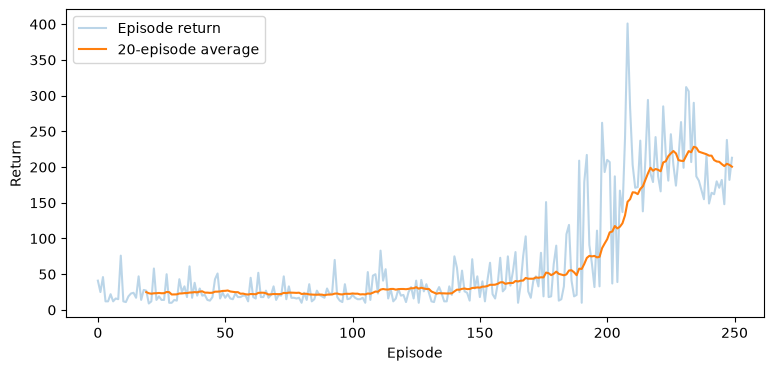

In [18]:
# 학습이 불안정하면 에피소드 수, 탐험률, 학습률 등 확인
plt.figure(figsize=(9,4))
plt.plot(train_returns,alpha=.3,label='Episode return')
if len(train_returns)>=20:
    plt.plot(np.arange(19,len(train_returns)),np.convolve(train_returns,np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()

In [19]:
def evaluate_cartpole(model, episodes=10, seed=9000):
    env = gym.make('CartPole-v1')
    scores = []
    model.eval()
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        total = 0
        while True:
            with torch.no_grad():
                # 관측 4개를 (1, 4) 형태로 만듦
                x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                action = int(model(x).argmax(dim=1).item())
            state, r, terminated, truncated, _ = env.step(action)
            total += r
            if terminated or truncated: break
        scores.append(total)
    env.close()
    return scores

In [20]:
scores = evaluate_cartpole(trained_q)
print('평가 점수:', scores)
print(f'평균={np.mean(scores):.1f}, 표준편차={np.std(scores):.1f}')

평가 점수: [221.0, 295.0, 210.0, 208.0, 245.0, 310.0, 237.0, 243.0, 227.0, 210.0]
평균=240.6, 표준편차=33.6


> 학습이 진행될수록 에피소드별 누적 보상(Return)이 증가하고, 높은 보상이 안정적으로 유지된다면 학습이 잘 되고 있다고 판단

> 학습 그래프가 좋아 보이는 것과 실제 모델이 잘 학습된 것은 다름 > evaluate_cartpole()로 평가

### CartPole에서 학습이 잘 되고 있는지 체크
- 매 스텝마다 일반적으로 보상 +1
- 막대가 넘어지거나 수레가 허용 위치를 벗어나면 종료
- 최대 500스텝까지 진행
- 한 에피소드의 최대 누적 보상은 500점

```
10 ~ 30: 거의 학습되지 않은 수준
30 ~ 100: 일부 행동을 학습했을 가능성
100 ~ 200: 균형 유지 능력이 개선되는 단계
200 ~ 400: 좋은 성능
400 ~ : 최대 성능
```

> DQN 학습이 잘 되었다는 것은 Loss가 작아지는 것만을 의미하진 않음. 가장 중요한 것은 학습된 신경망이 실제 환경에서 좋은 행동을 선택하고, 여러 번 평가했을 때 누적 보상을 안정적으로 얻는 것

# **3. Policy Gradient**

```
달리는 캐릭터 앞에 장애물이 있음(가능 행동 0=대기, 1=점프)
- 학습 전: 점프 50%, 대기 50% > 결과는 아직 잘 모름
- 점프해서 장애물을 피함 > 좋은 결과를 경험
- 비슷한 상황을 반복 학습한 뒤 > 점프 90%, 대기 10%
```

> 정책은 '항상 점프'가 아님. 장애물이 멀면 대기가 좋을 수 있고, 가까우면 점프가 좋을 수 있음. 따라서 신경망은 현재 상태를 입력받아 행동별 확률을 출력

- $π(a|s)$: 상태 s일 때 행동 a를 선택할 확률
- $θ$: 신경망의 가중치, 즉 학습하면서 바뀌는 숫자들
- $πθ(a|s)$: 신경망 가중치 θ가 정하는 행동 확률

> 확률 90%는 90%의 성공률과 다름. 점프를 선택할 확률일 뿐

In [21]:
before = np.array([0.5, 0.5])
after  = np.array([0.1, 0.9])
for name, p in [('학습 전', before), ('학습 후(가상)', after)]:
    print(f'{name}: 대기 {p[0]*100:.0f}%, 점프 {p[1]*100:.0f}%, 합계 {p.sum():.1f}')

학습 전: 대기 50%, 점프 50%, 합계 1.0
학습 후(가상): 대기 10%, 점프 90%, 합계 1.0


### DQN vs 정책 신경망

- DQN: 행동의 예상 점수를 계산하고 높은 쪽으로 고름. 예) 현재 상태 > 신경망 > [대기 Q=2, 점프=6]
- 정책 신경망: 행동을 선택할 확률을 계산하고 그 확률에 따라 행동을 뽑을 수 있음. 예) 현재 상태 > 신경망 > [대기 20%, 점프 80%]

> 둘 다 신경망 가중치를 실제로 학습. 다만 출력의 의미와 학습 목표가 다름. DQN에서의 ε-greedy는 탐험을 위한 별도 규칙이지만, 정책 신경망은 행동 확률 자체를 배움

> 정책 기반이라고 해서 항상 무작위 행동만 하는 것은 아님. 평가할 때는 가장 확률이 높은 행동을 선택하기도 함

### 학습의 순서

1. 현재 상황 관측. 예) 장애물 거리, 캐릭터 속도
2. 정책 신경망이 확률 계산. 예) 대기 40%, 점프 60%
3. 행동 선택. 예) 이번에는 점프
4. 실행. 예) 장애물을 피해서 보상 + 10
5. 경험으로 학습 신호 만들기. 예) 이번 행동이 좋은 결과와 연결됐다는 정보
6. 손실함수 계산/역전파/가중치 수정. 예) 비슷한 상황에서 점프 확률을 높이는 방향으로 학습할 수 있음
7. 다시 게임 실행. 예) 많은 경험을 반복하며 정책 개선

In [22]:
from torch.distributions import Categorical, Normal

In [23]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.Tanh(),
            nn.Linear(64, n_actions)
        )

    def forward(self, x):
        return self.net(x)

In [24]:
policy_demo = PolicyNet().to(DEVICE)
state_demo = torch.tensor([[0.0, 0.1, 0.02, -0.03]], dtype=torch.float32, device=DEVICE)
logits = policy_demo(state_demo)
# Categotical: 0. 1 처럼 이산 행동의 확률 분포
# Normal: 연속 행동의 정규 분포
# logits는 확률 이전의 점수 > softmax를 적용하면 합계가 1인 확률 > Categorical로 실제 행동을 추첨
dist = Categorical(logits=logits)
a = dist.sample()
print('logits:', logits.detach().cpu().numpy())
print('확률:', dist.probs.detach().cpu().numpy())
print('행동:', a.item(), 'log_prob:', dist.log_prob(a).item())

logits: [[ 0.2250176  -0.02445354]]
확률: [[0.56204635 0.43795368]]
행동: 0 log_prob: -0.5761709809303284


### 한 에피소드가 끝난 뒤 학습

- 순서: reset() >> 행동 샘플 >> step >> (log_prob, reward) 저장 >> 종료 >> G_t 계산 >> loss.backward() >> optimizer.step()
- 미래 보상을 실제 에피소드 결과에서 계산하므로 신경망으로 다음 상태 가치를 부트스트랩하지 않음
- 에피소드 전체를 기다려야 하고 결과 변동이 큰 편
- 예) 보상이 [1, 1, 1], $γ$=0.9 이면 마지막 시점 $G_2=1$, $G_1=1 + 0.9 \times 1 = 1.9$, $G_0 = 1 + 0.9 \times 1.9 = 2.71$
- 첫 행동은 이후 보상까지 반영

In [25]:
def discounted_returns(rewards,gamma=0.99):
    out=[]; running=0.0
    for r in reversed(rewards):
        running=float(r)+gamma*running
        out.append(running)
    return list(reversed(out))
print('예시:',discounted_returns([1,1,1],gamma=0.9))

예시: [2.71, 1.9, 1.0]


In [26]:
'''
                        DQN                              REINFORCE
저장:               Replay Buffer                 현재 한 판의 logps, rewards
학습:                일정 스텝마다                        한 판 종료 후
방식:                Q값 예측 개선                    행동 선택 확률 개선
과거 경험 재사용:         가능                              하지 않음
'''

def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        logps = []
        rewards = []
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            dist = Categorical(logits=net(x))
            a = dist.sample()
            next_state, reward, terminated, truncated, _ = env.step(int(a.item()))

            # 로그 확률을 사용하면 선택한 행동의 확률을 높이거나 낮추기 위한 신경망의 기울기를 계산하기 편리하기 때문
            logps.append(dist.log_prob(a).squeeze())
            rewards.append(float(reward))
            state = next_state
            if terminated or truncated: break
        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)
        if len(G) > 1:
            G = (G-G.mean()) / (G.std(unbiased=False)+1e-8)
        loss = -(torch.stack(logps) * G).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scores.append(sum(rewards))
        if (ep+1)%30==0:print(f'REINFORCE {ep+1}/{episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return net, scores

REINFORCE 30/250 | 최근 20회 평균 23.2
REINFORCE 60/250 | 최근 20회 평균 29.8
REINFORCE 90/250 | 최근 20회 평균 32.9
REINFORCE 120/250 | 최근 20회 평균 38.5
REINFORCE 150/250 | 최근 20회 평균 47.0
REINFORCE 180/250 | 최근 20회 평균 73.0
REINFORCE 210/250 | 최근 20회 평균 77.8
REINFORCE 240/250 | 최근 20회 평균 140.6


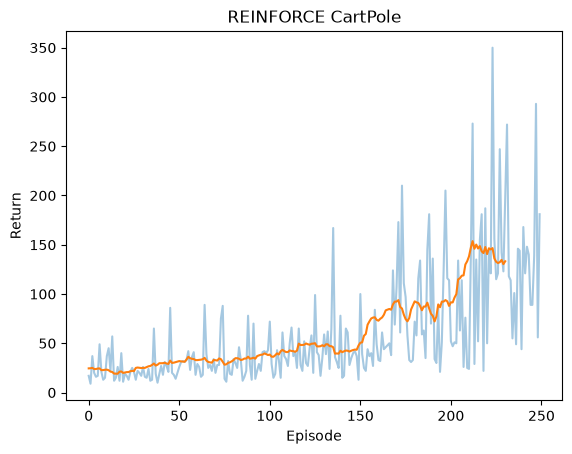

In [27]:
reinforce_model,reinforce_scores=train_reinforce(episodes=250)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

# **4. Actor-Critic**

```
1. 캐릭터가 한 판을 끝까지 플레이함
2. 어떤 행동을 했고, 어떤 보상을 받았는지 기록
3. 그 시점 이후 얻은 보상(리턴)을 이용해 행동 확률을 조정
```
- 위 내용이 REINFORCE 핵심
- 성공에 이르는 과정의 행동들을 학습에 반영. 예) 5번 점프하고 스테이지를 모두 클리어 함
- 한 판이 끝나야 업데이트하는 기본형은 보상 변동이 커서 학습이 불안정할 수 있음
- 잘했는지 판단하는 기준이 부족 > Actor-Critic의 등장

- Actor: 지금 어떤 행동을 할지 정함. 예) 점프 70%, 대기 30%
- Critic: 현재 상황이 앞으로 얼마나 유리한지 평가. 예) V(s)=5

> 예상보다 결과가 좋으면 > 선택한 행동의 확률을 높이는 학습 신호

> 예상보다 결과가 나쁘면 > 선택한 행동의 확률을 낮추는 학습 신호

> Critic의 예측은 정답이 아니라 학습 중인 추정치. 평가도 틀릴 수 있음

```
장애물 피하기 게임
1. 캐릭터 앞에 장애물이 나타남. (State, 상태)
2. Actor가 점프 70%, 대기 30%를 출력하고 행동을 하나 뽑음. (Policy, 정책)
3. Critic은 현재 상황에서 앞으로 얻을 할인된 보상의 기댓값을 예측함. 예: V(s) = 4
4. 실제로 행동한 뒤 보상 r과 다음 상태 s'을 관찰함
5. Critic의 새 예측을 이용해 TD 오차 δ를 계산하고, Actor와 Critic을 각각 학습
```

> Critic이 정답을 아는 것은 아님. Critic도 경험을 통해 예측을 고쳐 나감

1. Actor 출력
- 상태 s에서 행동 a를 선택할 확률
- 확률 70%라는 것은 무조건 점프한다는 뜻이 아님
- DQN의 $Q(s, a)$는 행동별 가치, Actor의 $π(a|s)$는 행동별 확률이므로 서로 다름

2. Critic의 출력
- 상태 가치 V(s)를 출력.
- 현재 상태에서 정책을 따를 때 앞으로 얻을 할인된 보상의 기댓값

$$
\delta = r + \gamma(1-done)V(s') - V(s)
$$

> $\delta$는 TD 오차. 새로 계산한 TD 목표 - Critic이 이전에 예측한 현재 가치

- 게임이 끝나지 않았다면(done=0) -> $δ = r + γV(s') - V(s)$
- 게임이 끝났다면 (done=1) -> $δ = r - V(s)$

```
게임이 아직 끝나지 않았고 아래의 내용을 참고
- 현재 가치 V(s) = 4
- 점프 직후 보상 r = 1
- 다음 상태 가치 V(s') = 6
- 할인율 γ = 0.9
- done = 0
```

- TD 목표값 = $r + γV(s')$ = 6.4
- $\theta$ = 6.4 - 4 = 2.4

> Critic이 예상한 4보다 TD 목표 6.4가 높음. Actor는 방금 선택한 점프의 확률을 높이는 방향으로, Critic은 4라는 예측을 6.4에 가깝게 만드는 방향으로 학습

> 2.4는 확률이 2.4% 증가한다는 뜻이 아님. 실제 변화량은 신경망과 학습률에 따라 달라짐. Critic의 예측이 부정확할 수 있으므로 정답이 아니라 학습 신호

$$
L_{actor}=-\log\pi(a|s)\,\mathrm{stopgrad}(\delta)
$$

$$
L_{critic}=(V(s)-\mathrm{stopgrad}(r+\gamma(1-done)V(s')))^2
$$

- stopgrad는 해당 값을 상수처럼 취급하여 그 경로로 역전파하지 않는다는 의미(detach(), torch.no_grad())

In [28]:
def td_error(value, reward, next_value, gamma=0.9, done=False):
    target = reward + gamma * (1 - int(done)) * next_value
    delta = target - value
    return target, delta

cases = [
    ("예상보다 좋음", 4, 1, 6, 0.9, False),
    ("예상보다 나쁨", 5, 2, 4, 0.5, False),
    ("종료 상태", 4, 1, 100, 0.9, True),
]
for name, v, r, next_v, gamma, done in cases:
    target, delta = td_error(v, r, next_v, gamma, done)
    print(f"{name}: TD 목표={target:.2f}, 현재 예측={v:.2f}, δ={delta:+.2f}")

예상보다 좋음: TD 목표=6.40, 현재 예측=4.00, δ=+2.40
예상보다 나쁨: TD 목표=4.00, 현재 예측=5.00, δ=-1.00
종료 상태: TD 목표=1.00, 현재 예측=4.00, δ=-3.00


In [29]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh()
        )
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h).squeeze(-1)

In [30]:
ac_demo = ActorCriticNet().to(DEVICE)
lg, val = ac_demo(state_demo)
print('Actor logits:', lg.shape, 'Critic V(s):', val.shape)

Actor logits: torch.Size([1, 2]) Critic V(s): torch.Size([1])


In [31]:
import torch.nn.functional as F

In [32]:
ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=1e-3)
s = torch.zeros((1, 4), device=DEVICE)
s2 = torch.tensor([[0.02, 0.1, -0.03, 0.02]], device=DEVICE)

logits, value = ac(s)
dist = Categorical(logits=logits)
a = dist.sample()

with torch.no_grad():
    _, next_value = ac(s2)
    td_target = torch.tensor([1.0], device=DEVICE) + 0.99 * next_value

advantage = td_target - value
actor_loss = -(dist.log_prob(a) * advantage.detach()).mean()
critic_loss = F.mse_loss(value, td_target)
# 0.5는 두 손실의 상대 가중치
loss = actor_loss + 0.5 * critic_loss
opt.zero_grad()
loss.backward()
opt.step()
print('선택 행동:',a.item(),'TD 목표:',td_target.item(),'Advantage:',advantage.item(),'Loss:',loss.item())

선택 행동: 0 TD 목표: 1.0370668172836304 Advantage: 0.9830765724182129 Loss: 1.2196718454360962


### Advantage
$A(s, a) = Q(s, a) - V(s)$

- Q: 특정 행동의 예상 가치
- V: 그 상태에서 정책을 다를 때의 평균적인 예상 가치
- Actor-Critic 코드에서는 $r + γV(s') - V(s)$ 같은 TD 오차를 Advantage의 추정값으로 사용
- Advantage는 받은 보상 r이 아님. 기대와 비교한 차이

In [33]:
expected = 5.0
for name, estimated_action_value in [('점프', 8.0), ('대기', 3.0)]:
    advantage = estimated_action_value - expected
    print(f'{name}: 행동가치 {estimated_action_value:.1f} - 상태가치 {expected:.1f} = Advantage {advantage:+.1f}')

점프: 행동가치 8.0 - 상태가치 5.0 = Advantage +3.0
대기: 행동가치 3.0 - 상태가치 5.0 = Advantage -2.0


### REINFORCE CartPole을 Actor-Critic으로 변경

- REINFORCE는 에피소드가 끝난 뒤 할인 리턴을 계산했지만, Actor-Critic은 매 스텝 TD 오차로 업데이트
- PolicyNet 대신 Actor의 logit 2개 + Critic의 상태 가치 1개를 출력하는 ActorCriticNet을 사용
- 학습 보상 곡선을 REINFORCE와 비교함

1. ActorCriticNet을 이용해 행동 확률과 상태 가치 V(s)를 출력
2. Categorical(logits=logits)로 행동을 샘플링하고 환경에서 한 스텝을 실행
3. 250개 에피소드 동안 학습하고, 각 에피소드 보상과 최근 20회 이동평균을 그림
4. 이미 학습한 reinforce_scores와 두 학습 곡선을 비교

In [34]:
def train_actor_critic_answer(episodes=250, seed=2026, gamma=0.9, lr=1e-9):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    model = ActorCriticNet().to(DEVICE)
    optimizer = optim.Adam((model).parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        score = 0.0
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x)  # logits = Actor logits, value = Critic V(s)
            dist = Categorical(logits=logits)
            action = dist.sample()    # 0: 왼쪽, 1: 오른쪽
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            loss = actor_loss + 0.5 * critic_loss
            
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            score += float(reward)
            state = next_state
            if terminated or truncated:
                break

        scores.append(score)
        if (ep + 1) % 30 == 0:
            print(f'Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return model, scores

In [35]:
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams['axes.unicode_minus'] = False

Actor-Critic 30 / 250 | 최근 20회 평균 26.4
Actor-Critic 60 / 250 | 최근 20회 평균 16.0
Actor-Critic 90 / 250 | 최근 20회 평균 16.3
Actor-Critic 120 / 250 | 최근 20회 평균 20.2
Actor-Critic 150 / 250 | 최근 20회 평균 19.2
Actor-Critic 180 / 250 | 최근 20회 평균 20.1
Actor-Critic 210 / 250 | 최근 20회 평균 15.8
Actor-Critic 240 / 250 | 최근 20회 평균 20.3


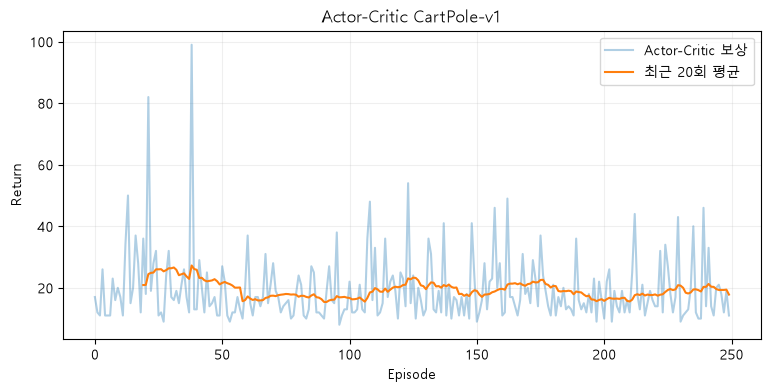

In [36]:
ac_cartpole_model, ac_cartpole_scores = train_actor_critic_answer()
plt.figure(figsize=(9, 4))
plt.plot(ac_cartpole_scores, alpha=0.35, label='Actor-Critic 보상')
if len(ac_cartpole_scores) >= 20:
    ma = np.convolve(ac_cartpole_scores, np.ones(20)/20, mode='valid')
    plt.plot(np.arange(19, len(ac_cartpole_scores)), ma, label='최근 20회 평균')
plt.xlabel('Episode'); plt.ylabel('Return'); plt.title('Actor-Critic CartPole-v1')
plt.legend(); plt.grid(alpha=0.2); plt.show()

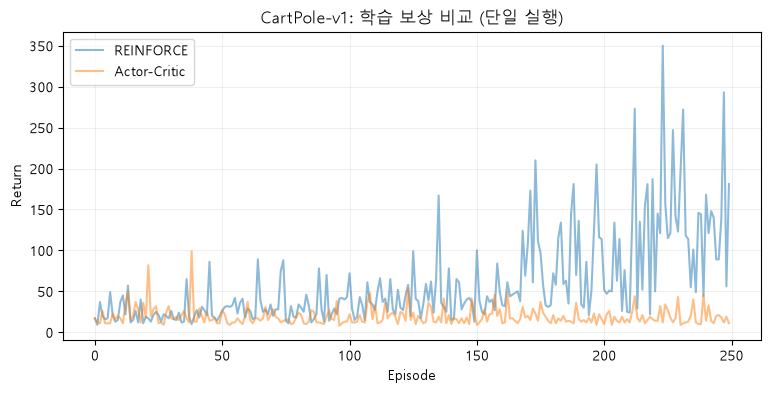

최근 20회 평균 REINFORCE: 133.2
최근 20회 평균 Actor-Critic: 17.8


In [37]:
plt.figure(figsize=(9, 4))
plt.plot(reinforce_scores, alpha=0.5, label='REINFORCE')
plt.plot(ac_cartpole_scores, alpha=0.5, label='Actor-Critic')
plt.xlabel('Episode'); plt.ylabel('Return')
plt.title('CartPole-v1: 학습 보상 비교 (단일 실행)')
plt.legend(); plt.grid(alpha=0.2); plt.show()
print('최근 20회 평균 REINFORCE:', round(float(np.mean(reinforce_scores[-20:])), 1))
print('최근 20회 평균 Actor-Critic:', round(float(np.mean(ac_cartpole_scores[-20:])), 1))

### REINFORCE vs Actor-Critic 비교

1. REINFORCE
- 에피소드가 끝난 뒤 누적보상을 계산
- 실제 경험에서 얻은 리턴을 이용해 정책을 학습
- 리턴의 분산은 클 수 있지만, Critic의 가치 예측 오차에 영향을 받지 않음

2. Actor-Critic
- 매 스탭 TD 오차를 계산
- Critic의 가치 예측을 이용해 Actor를 학습
- Critic의 예측이 부정확하면 Actor도 잘못된 방향으로 업데이트 될 수 있음

### Actor-Critic의 성능을 높이려면?
- 학습 횟수를 늘리고, 학습률을 낮춤

# **5. Actor-Critic을 이용한 달 착륙 AI 개발**

Gymnasium을 이용하여 우주선이 스스로 엔진을 제어하고 안전하게 착륙하도록 학습하는 강화학습 시스템을 개발

### 1. 프로젝트 시나리오
- 달 표면에 착륙할 우주선은 처음에는 엔진을 언제 사용해야 하는지 알지 못함
- 너무 빠르게 하강하면 추락하고, 좌우 균형을 잡지 못하면 착륙 지점을 벗어날 수 있음
    - 우주선의 현재 위치와 속도를 분석
    - 우주선의 기울기와 회전 속도를 확인
    - 엔진을 사용하거나 사용하지 않는 행동을 선택
    - 행동 결과로 받은 보상을 이용하여 Actor와 Critic을 학습
    - 반복 학습을 통해 안전한 착륙을 시도

### 2. 개발 환경
- Gymnasium의 LunarLander-v3 환경
```
python -m pip install "gymnasium[box2d]"
```

### 3. 상태 데이터
LunarLander-v3는 매 스텝마다 8개의 숫자로 구성된 상태 벡터를 반환
```
0: 착륙 지점을 기준으로 한 좌우 위치
1: 착륙 지점을 기준으로 한 높이
2: 좌우 이동 속도
3: 상하 이동 속도
4: 우주선이 기울어진 각도
5: 우주선의 회전 속도
6: 왼쪽 착륙 다리가 지면에 닿았는지
7: 오른쪽 착륙 다리가 지면에 닿았는지
```

### 4. 행동 데이터
```
0: 엔진 사용 안 함: 중력 등에 따라 자연스럽게 이동
1: 왼쪽 보조 엔진: 우주선의 자세와 이동에 영향을 줌
2: 주 엔진: 주로 하강 속도를 제어하는 데 사용
3: 오른쪽 보조 엔진: 우주선의 자세와 이동에 영향을 줌
```

### 5. 보상 데이터
- LunarLander는 단순히 착륙 성공과 실패만 평가하지 않음
- 착륙 지점까지의 거리, 속도, 기울기, 착륙 다리 접촉, 엔진 사용량 등을 함께 고려
    - 착륙 지점에 가까워짐
    - 이동 속도가 줄어듦
    - 우주선의 기울기가 커짐
    - 착륙 다리 접촉|
    - 주 엔진 사용
    - 보조 엔진 사용
    - 추락: -100
    - 안전한 착륙: 100

In [38]:
lunar = gym.make('LunarLander-v3', render_mode='human')
lunar

<TimeLimit<OrderEnforcing<PassiveEnvChecker<LunarLander<LunarLander-v3>>>>>

In [39]:
def train_lunarlander(episodes=250, seed=2026, gamma=0.9, lr=1e-9):
    torch.manual_seed(seed)
    env = gym.make('LunarLander-v3')
    model = ActorCriticNet().to(DEVICE)
    optimizer = optim.Adam((model).parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        score = 0.0
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x)  # logits = Actor logits, value = Critic V(s)
            dist = Categorical(logits=logits)
            action = dist.sample()    # 0: 왼쪽, 1: 오른쪽
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            loss = actor_loss + 0.5 * critic_loss
            
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            score += float(reward)
            state = next_state
            if terminated or truncated:
                break

        scores.append(score)
        if (ep + 1) % 30 == 0:
            print(f'Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return model, scores

In [40]:
# import torch
# import torch.nn as nn
# import torch.optim as optim
# import torch.nn.functional as F
# import gymnasium as gym
# import numpy as np

# # ==========================================
# # 1. Actor-Critic 신경망 모델 정의
# # ==========================================
# class ActorCritic(nn.Module):
#     def __init__(self, state_dim=8, action_dim=4):
#         super(ActorCritic, self).__init__()
        
#         # 공통 특징 추출 레이어
#         self.fc_shared = nn.Linear(state_dim, 128)
        
#         # Actor 네트워크 (정책: 각 행동에 대한 확률 분포 출력)
#         self.actor = nn.Sequential(
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Linear(64, action_dim),
#             nn.Softmax(dim=-1)
#         )
        
#         # Critic 네트워크 (가치 함수: 현재 상태의 가치 V(s) 평가)
#         self.critic = nn.Sequential(
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Linear(64, 1)
#         )

#     def forward(self, state):
#         x = F.relu(self.fc_shared(state))
#         action_probs = self.actor(x)
#         state_value = self.critic(x)
#         return action_probs, state_value


# # ==========================================
# # 2. 에이전트 및 학습 로직 구현
# # ==========================================
# def train_lunar_lander():
#     # 2. 개발 환경 설정
#     env = gym.make("LunarLander-v3", render_mode='human')
    
#     state_dim = env.observation_space.shape[0]  # 8개 상태 데이터
#     action_dim = env.action_space.n             # 4개 행동 데이터
    
#     model = ActorCritic(state_dim, action_dim)
#     optimizer = optim.Adam(model.parameters(), lr=0.001)
#     gamma = 0.99  # 할인율
    
#     num_episodes = 1000

#     print("=== LunarLander-v3 Actor-Critic 학습 시작 ===")

#     for episode in range(1, num_episodes + 1):
#         state, info = env.reset()
#         done = False
#         truncated = False
        
#         log_probs = []
#         values = []
#         rewards = []
        
#         episode_reward = 0

#         while not (done or truncated):
#             # 상태 전처리
#             state_tensor = torch.FloatTensor(state).unsqueeze(0)
            
#             # Actor-Critic 순전파
#             action_probs, state_value = model(state_tensor)
            
#             # 확률 분포에 따라 행동 선택
#             dist = torch.distributions.Categorical(action_probs)
#             action = dist.sample()
            
#             # 환경 내 행동 실행
#             next_state, reward, done, truncated, _ = env.step(action.item())
            
#             # 히스토리 기록
#             log_probs.append(dist.log_prob(action))
#             values.append(state_value)
#             rewards.append(reward)
            
#             state = next_state
#             episode_reward += reward

#         # Discounted Reward (리턴 G_t) 계산
#         returns = []
#         G = 0
#         for r in reversed(rewards):
#             G = r + gamma * G
#             returns.insert(0, G)
            
#         returns = torch.tensor(returns)
#         # 정규화하여 학습 안정성 확보
#         returns = (returns - returns.mean()) / (returns.std() + 1e-8)
        
#         # 손실 함수 계산 (Advantage = Return - Value)
#         actor_loss = 0
#         critic_loss = 0
        
#         for log_prob, value, R in zip(log_probs, values, returns):
#             advantage = R - value.item()
#             actor_loss += -log_prob * advantage
#             critic_loss += F.mse_loss(value.squeeze(), R)

#         total_loss = actor_loss + critic_loss

#         # 역전파 및 경사하강법 적용
#         optimizer.zero_grad()
#         total_loss.backward()
#         optimizer.step()

#         # 학습 결과 출력
#         if episode % 20 == 0:
#             print(f"Episode {episode:4d} | Total Reward: {episode_reward:7.2f} | Loss: {total_loss.item():.4f}")

#     env.close()

# if __name__ == "__main__":
#     train_lunar_lander()

In [41]:
# import torch
# import torch.nn as nn
# import torch.optim as optim
# import torch.nn.functional as F
# import gymnasium as gym


# # 1. Actor-Critic 신경망
# class ActorCritic(nn.Module):
#     def __init__(self, state_dim=8, action_dim=4):
#         super().__init__()

#         self.fc_shared = nn.Linear(state_dim, 128)

#         # Softmax 대신 logits 출력
#         self.actor = nn.Sequential(
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Linear(64, action_dim)
#         )

#         self.critic = nn.Sequential(
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Linear(64, 1)
#         )

#     def forward(self, state):
#         x = F.relu(self.fc_shared(state))
#         return self.actor(x), self.critic(x)


# # 2. 학습
# def train_lunar_lander():
#     # 학습 속도를 위해 화면 표시 제거
#     env = gym.make("LunarLander-v3")

#     model = ActorCritic(
#         state_dim=env.observation_space.shape[0],
#         action_dim=env.action_space.n
#     )
#     optimizer = optim.Adam(model.parameters(), lr=0.0003)

#     gamma = 0.99
#     num_episodes = 1000
#     value_coef = 0.5
#     entropy_coef = 0.01

#     print("=== LunarLander-v3 Actor-Critic 학습 시작 ===")

#     try:
#         for episode in range(1, num_episodes + 1):
#             state, _ = env.reset()

#             log_probs = []
#             values = []
#             rewards = []
#             entropies = []
#             episode_reward = 0.0

#             while True:
#                 state_tensor = torch.as_tensor(
#                     state, dtype=torch.float32
#                 ).unsqueeze(0)

#                 logits, state_value = model(state_tensor)
#                 dist = torch.distributions.Categorical(logits=logits)
#                 action = dist.sample()

#                 next_state, reward, terminated, truncated, _ = env.step(
#                     action.item()
#                 )

#                 log_probs.append(dist.log_prob(action))
#                 values.append(state_value)
#                 rewards.append(reward)
#                 entropies.append(dist.entropy())

#                 state = next_state
#                 episode_reward += reward

#                 if terminated or truncated:
#                     break

#             # 실제 종료에서는 0, 시간 제한 종료에서는 마지막 상태 가치 사용
#             with torch.no_grad():
#                 G = 0.0
#                 if not terminated:
#                     final_state = torch.as_tensor(
#                         state, dtype=torch.float32
#                     ).unsqueeze(0)
#                     _, final_value = model(final_state)
#                     G = final_value.item()

#             # 앞쪽 삽입 대신 append 후 역순으로 변환
#             returns = []
#             for reward in reversed(rewards):
#                 G = reward + gamma * G
#                 returns.append(G)
#             returns.reverse()

#             returns = torch.tensor(returns, dtype=torch.float32)
#             values = torch.cat(values).squeeze(-1)
#             log_probs = torch.cat(log_probs)
#             entropies = torch.cat(entropies)

#             # Critic 목표는 유지하고 Actor용 Advantage만 정규화
#             advantages = returns - values.detach()
#             advantages = (
#                 advantages - advantages.mean()
#             ) / (advantages.std(unbiased=False) + 1e-8)

#             actor_loss = -(log_probs * advantages).mean()

#             # 큰 가치 예측 오차의 영향을 완화
#             critic_loss = F.smooth_l1_loss(values, returns)

#             # 엔트로피 보너스로 탐험 유지
#             total_loss = (
#                 actor_loss
#                 + value_coef * critic_loss
#                 - entropy_coef * entropies.mean()
#             )

#             optimizer.zero_grad(set_to_none=True)
#             total_loss.backward()
#             torch.nn.utils.clip_grad_norm_(
#                 model.parameters(), max_norm=0.5
#             )
#             optimizer.step()

#             if episode % 20 == 0:
#                 print(
#                     f"Episode {episode:4d} | "
#                     f"Total Reward: {episode_reward:8.2f} | "
#                     f"Loss: {total_loss.item():.4f}"
#                 )
#     finally:
#         env.close()

#     return model


# model = train_lunar_lander()

In [42]:
# continuous=False: 이산 행동 공간 (default가 False)
env = gym.make("LunarLander-v3", continuous=False)
state, info = env.reset(seed=2026)
print('상태 공간:', env.observation_space)
print('행동 공간:', env.action_space)
print('상태 shape:', state.shape, "| dtype:", state.dtype)
print('행동 수:', env.action_space.n)

상태 공간: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
행동 공간: Discrete(4)
상태 shape: (8,) | dtype: float32
행동 수: 4


### Actor와 Critic의 역할
- Actor는 $\pi(a|s)$라는 정책을 학습. "이 상태에서 각 행동을 얼마나 자주 선택할까?"를 결정
- Critic은 $V(s)$를 학습. "현재 상태에서 앞으로 받을 할인 보상은 얼마나 될까?"를 예측

$$
y_t=r_{t+1}+\gamma(1-\mathrm{terminated})V(s_{t+1})
$$

- $r$: 이번 행동으로 실제 받은 보상  
- $(1-\mathrm{terminated})$: 다음 상태에서 앞으로 받을 보상에 대한 현재 추정  
- $terminated=True$: 다음 상태의 가치를 더하지 않음

### TD 오차(델타)

$$
\delta_t=y_t-V(s_t)
$$

- $\delta$ > 0 : Critic의 예상보다 실제 한 스텝 결과가 좋음 -> 선택한 행동을 강화할 신호
- $\delta$ < 0 : 예상보다 나쁨 -> 선택한 행동의 확률을 낮출 신호

> Critic이 틀릴 수도 있기 때문에 $\delta$는 완벽한 정답이 아님

### Actor Loss

$$
L_{actor}=-\log\pi(a_t|s_t)\,\mathrm{stopgrad}(\delta_t)
$$

> log_prob(action)은 실제로 선택한 행동의 로그 확률. delta.detach()는 actor가 critic의 TD 오차를 역전파 경로로 직접 바꾸지 못하게 막음


### Critic Loss

$$
L_{critic}=(V(s_t)-\mathrm{stopgrad}(y_t))^2
$$

> 현재 가치 예측이 TD 목표에 가까워지도록 평균제곱오차(MSE)를 최소화

### 전체 Loss

$$
L=L_{actor}+\beta L_{critic}-\eta H(\pi(\cdot|s))
$$

- β: Critic 손실비중
- η: 엔트로피 보너스의 비중
- H: 정책의 불확실성. 지나친 조기 확신을 억제할 때 사용

> 전체 손실 L은 엑터 손실에 베타 곱하기 크리틱 손실을 더하고, 에타 곱하기 엔트로피 에이치를 뺀 값

> 손실을 더하는 이유는 두 손실을 통해 공통 신경망을 포함한 파라미터를 함께 업데이트하기 때문

In [43]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, x):
        features = self.body(x)
        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)
        return logits, value

In [44]:
model_test = ActorCriticNet().to(DEVICE)
dummy = torch.randn(3, 8, device=DEVICE)
logits, values = model_test(dummy)
print('입력:', dummy.shape, "logits:", logits.shape, "V(s):", values.shape)
print('샘플 행동 확률:', torch.softmax(logits, dim=-1).detach().cpu().numpy())

입력: torch.Size([3, 8]) logits: torch.Size([3, 4]) V(s): torch.Size([3])
샘플 행동 확률: [[0.23734003 0.24780063 0.2579919  0.25686747]
 [0.21335296 0.28249577 0.2501287  0.2540227 ]
 [0.22459811 0.27294812 0.25361085 0.24884291]]


In [45]:
def run_random_baseline(episodes=20, seed=1000):
    env = gym.make('LunarLander-v3', continuous=False)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        env.action_space.seed(seed+ep)
        score = 0.0
        while True:
            action = env.action_space.sample()
            state, reward, terminated, truncated, _ = env.step(action)
            score += float(reward)
            if terminated or truncated:
                break

        scores.append(score)

    env.close()
    return scores

In [46]:
random_scores = run_random_baseline(episodes=20)
print('랜덤 정책 20회 평균:', round(float(np.mean(random_scores)), 2))
print('최저/최고:', round(min(random_scores), 2), round(max(random_scores), 2))

랜덤 정책 20회 평균: -211.55
최저/최고: -371.19 -76.22


### 한 스텝 안에서 처리할 일
1. state를 float32 텐서 (1, 8)로 변환
2. model(x)에서 logits와 value를 얻음
3. Categotical(logits=logits).sample()로 행동을 뽑음
4. env.step(action)으로 실제 행동을 실행
5. 다음 상태를 Critic에 넣어 next_value를 구함. torch.no_grad()로 TD 목표의 역전파를 차단
6. td_target = reward + gamma * (not terminated) * next_value를 계산
7. delta = td_target - value를 계산
8. actor_loss는 delta.detach()를 사용
9. critic_loss는 MSE로 현재 가치와 TD 목표의 차이를 줄임
10. 학습
11. termindated, truncated이면 에피소드를 끝냄

In [47]:
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [48]:
import time
import pandas as pd

# episodes: 학습할 에피소드 수
# seed: 난수 생성의 기준값
# gamma: 미래 보상의 할인율
# lr: 신경망 학습률
# hidden: 은닉층의 뉴런 수
# max_steps: 한 에피소드에서 허용하는 최대 행동 횟수
# critic_coef: Critic 손실의 가중치
# entropy_coef: 탐색을 장려하는 엔트로피 보너스의 가중치
# print_every: 학습 결과를 출력하는 간격

def train_actor_critic(episodes=500, seed=2026, gamma=0.99, lr=3e-4, hidden=128, max_steps=1000, critic_coef=0.5, entropy_coef=0.0, print_every=50):
    set_seed(seed)
    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)
    model = ActorCriticNet(8, 4, hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores, lengths, actor_losses, critic_losses, entropies = [], [], [], [], []
    start = time.time()

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        score, steps = 0.0, 0
        ep_actor, ep_critic, ep_entropy = [], [], []

        for t in range(max_steps):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.as_tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            entropy = dist.entropy().mean()
            loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            score += float(reward)
            steps += 1
            state = next_state
            ep_actor.append(float(actor_loss.item()))
            ep_critic.append(float(critic_loss.item()))
            ep_entropy.append(float(entropy.item()))

            if terminated or truncated:
                break

        scores.append(score)
        lengths.append(steps)
        actor_losses.append(float(np.mean(ep_actor)))
        critic_losses.append(float(np.mean(ep_critic)))
        entropies.append(float(np.mean(ep_entropy)))

        if print_every and (ep+1) % print_every == 0:
            recent = np.mean(scores[-min(50,len(scores)):])
            print(f"Actor-Critic {ep+1:4d}/{episodes} | 최근 50회 평균 {recent:8.2f} | "
                  f"이번 보상 {score:8.2f} | {time.time()-start:.0f}s")

    env.close()
    history = pd.DataFrame({
        "episode": np.arange(1, episodes+1), "reward": scores,
        "steps": lengths, "actor_loss": actor_losses,
        "critic_loss": critic_losses, "entropy": entropies,
    })
    return model, history


In [49]:
AC_EPISODES = 500
ac_model, ac_history= train_actor_critic(episodes=AC_EPISODES, seed=2026, gamma=0.99, lr=3e-4, entropy_coef=0.0)

Actor-Critic   50/500 | 최근 50회 평균  -529.25 | 이번 보상  -142.07 | 7s
Actor-Critic  100/500 | 최근 50회 평균  -437.89 | 이번 보상  -811.05 | 14s
Actor-Critic  150/500 | 최근 50회 평균  -201.38 | 이번 보상   -80.24 | 25s
Actor-Critic  200/500 | 최근 50회 평균   -52.03 | 이번 보상  -145.25 | 36s
Actor-Critic  250/500 | 최근 50회 평균  -141.89 | 이번 보상    30.99 | 97s
Actor-Critic  300/500 | 최근 50회 평균     9.50 | 이번 보상   183.43 | 131s
Actor-Critic  350/500 | 최근 50회 평균    -2.99 | 이번 보상    16.15 | 178s
Actor-Critic  400/500 | 최근 50회 평균    26.07 | 이번 보상   -18.17 | 212s
Actor-Critic  450/500 | 최근 50회 평균    74.23 | 이번 보상   302.45 | 232s
Actor-Critic  500/500 | 최근 50회 평균    49.86 | 이번 보상     9.16 | 251s


In [50]:
ac_history

,episode,reward,steps,actor_loss,critic_loss,entropy
0,1,-13.035850,112,-0.429048,102.729744,1.208724
1,2,-307.481730,91,-3.400514,111.732093,0.731227
2,3,-484.663361,122,-2.257645,94.618944,0.981540
3,4,-514.041435,95,-1.898803,124.672576,0.724872
4,5,-611.482090,87,-4.057433,136.360960,0.835105
...,...,...,...,...,...,...
495,496,248.863974,408,0.078364,33.101247,0.430975
496,497,86.924938,781,-0.101528,13.633300,0.588545
497,498,219.237030,424,0.558439,30.363398,0.542342
498,499,33.967237,203,-0.062554,47.661177,0.505399


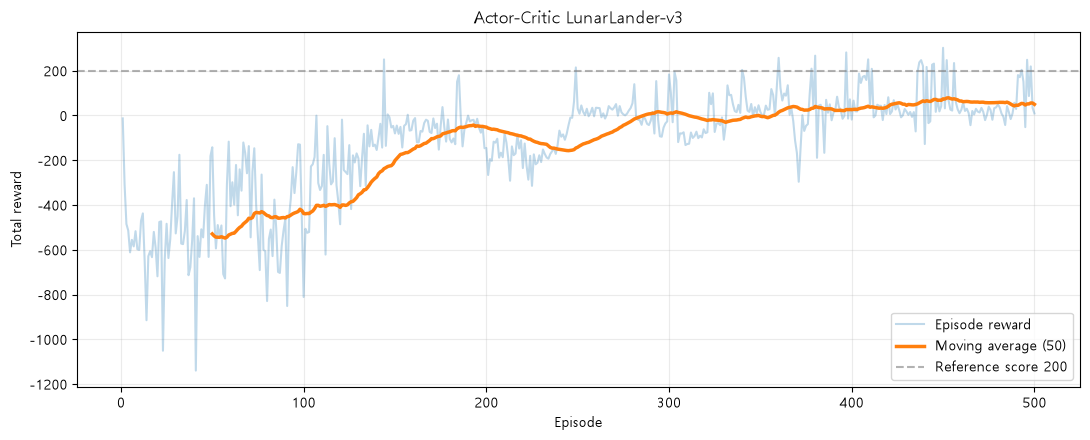

처음 50회 평균: -529.25
마지막 50회 평균: 49.86
전체 평균: -120.58
최고 에피소드 보상: 302.45
마지막 50회 평균 스텝: 261.7


In [52]:
def moving_average(values, window=50):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return np.array([]), np.array([])
    return np.arange(window, len(values)+1), np.convolve(values, np.ones(window)/window, mode="valid")

def plot_training(history, title="Actor-Critic LunarLander-v3", window=50):
    x = history["episode"].to_numpy()
    y = history["reward"].to_numpy()
    xx, yy = moving_average(y, window)
    plt.figure(figsize=(11,4.5))
    plt.plot(x, y, alpha=0.28, label="Episode reward")
    if len(xx):
        plt.plot(xx, yy, linewidth=2.5, label=f"Moving average ({window})")
    plt.axhline(200, linestyle="--", color="gray", alpha=0.6, label="Reference score 200")
    plt.xlabel("Episode"); plt.ylabel("Total reward"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

plot_training(ac_history)
print("처음 50회 평균:", round(ac_history.reward.head(50).mean(), 2))
print("마지막 50회 평균:", round(ac_history.reward.tail(50).mean(), 2))
print("전체 평균:", round(ac_history.reward.mean(), 2))
print("최고 에피소드 보상:", round(ac_history.reward.max(), 2))
print("마지막 50회 평균 스텝:", round(ac_history.steps.tail(50).mean(), 1))

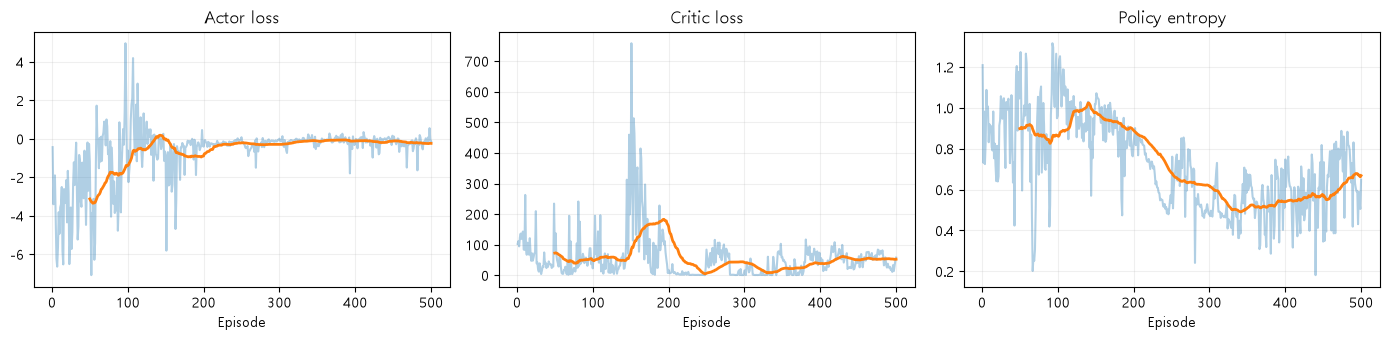

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(14,3.5))
for ax, col, title in zip(axes, ["actor_loss", "critic_loss", "entropy"], ["Actor loss", "Critic loss", "Policy entropy"]):
    ax.plot(ac_history.episode, ac_history[col], alpha=0.35)
    xx, yy = moving_average(ac_history[col], 50)
    if len(xx): ax.plot(xx, yy, linewidth=2)
    ax.set_title(title); ax.set_xlabel("Episode"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

- 학습 중에는 확률적으로 행동을 샘플링
- 학습 완료 후 평가에서는 정책을 고정하고, 아래 두 방식 중 하나를 선택
    - 결정적 평가(greedy=True): logits의 argmax()로 가장 확률이 높은 행동을 선택
    - 확률적 평가(greedy=False): Categorical에서 샘플링. 실제 학습 정책의 확률적 행동 성능 확인

In [54]:
next(model.parameters()).device

device(type='cpu')

In [55]:
model.parameters()

<generator object Module.parameters at 0x000002002A661700>

In [56]:
model.training

True

In [57]:
def evaluate_policy(model, episodes=30, seed=1000, greedy=True, max_steps=1000):
    env = gym.make("LunarLander-v3", continuous=False)
    device = next(model.parameters()).device
    was_training = model.training
    model.eval()
    records = []
    try:
        for ep in range(episodes):
            state, _ = env.reset(seed=seed+ep)
            total_reward = 0.0
            last_state = None
            
            for t in range(max_steps):
                x = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
                
                with torch.no_grad():
                    logits = model(x)[0]
                    action = logits.argmax(dim=-1) if greedy else Categorical(logits=logits).sample()
                state, reward, terminated, truncated, _ = env.step(int(action.item()))
                total_reward += float(reward)
                last_state = state
                if terminated or truncated:
                    break
                
            contacts = (float(last_state[6]), float(last_state[7])) if last_state is not None else (np.nan, np.nan)
            records.append({"episode": ep+1, "reward": total_reward, "steps": t+1,
                            "terminated": bool(terminated), "truncated": bool(truncated),
                            "left_contact_final": contacts[0], "right_contact_final": contacts[1]})
    
    finally:
        env.close()
        model.train(was_training)

    return pd.DataFrame(records)

In [58]:
ac_eval = evaluate_policy(ac_model, episodes=30, seed=1000, greedy=True)

In [59]:
ac_eval.head()

,episode,reward,steps,terminated,truncated,left_contact_final,right_contact_final
0,1,42.506983,182,True,False,1.0,1.0
1,2,9.380711,179,True,False,1.0,1.0
2,3,30.242391,196,True,False,1.0,1.0
3,4,2.183221,202,True,False,1.0,1.0
4,5,51.107438,148,True,False,1.0,1.0


In [60]:
print("Actor-Critic 평가 평균:", round(ac_eval.reward.mean(), 2))
print("평가 표준편차:", round(ac_eval.reward.std(), 2))
print("평균 스텝:", round(ac_eval.steps.mean(), 1))
print("보상 200 이상 비율 (착륙 성공률과는 다름):", round((ac_eval.reward >= 200).mean(), 3))

Actor-Critic 평가 평균: 20.62
평가 표준편차: 21.39
평균 스텝: 176.4
보상 200 이상 비율 (착륙 성공률과는 다름): 0.0


### REINFORCE 같은 환경에서 직접 구현하기

$$
G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_{k+1}
$$

$$
L_{PG}=-\frac1T\sum_t \log\pi(a_t|s_t)\widehat G_t
$$

In [61]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

def discounted_returns(rewards,gamma=0.99):
    out=[]
    G = 0.0
    for r in reversed(rewards):
        G = float(r)+gamma*G
        out.append(G)
    return list(reversed(out))

In [62]:
# normalize_returns: Return을 정규화하여 학습을 안정적으롤 진행핟록 설정하는 옵션

def train_reinforce(episodes=500, seed=2026, gamma=0.99, lr=3e-4, print_every=50):
    torch.manual_seed(seed)
    env = gym.make('LunarLander-v3')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        logps = []
        rewards = []
        for t in range(500): 
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            dist = Categorical(logits=net(x))
            a = dist.sample()
            next_state, reward, terminated, truncated, _ = env.step(int(a.item()))
            logps.append(dist.log_prob(a).squeeze())
            rewards.append(float(reward))
            state = next_state
            if terminated or truncated: break
        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)
        if len(G) > 1:
            G = (G-G.mean()) / (G.std(unbiased=False)+1e-8)
        loss = -(torch.stack(logps) * G).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scores.append(sum(rewards))
    
        # if print_every and (ep+1) % print_every==0:
        #     recent = np.mean(scores[-min(50,len(scores)):])
        #     print(f'REINFORCE {ep+1}/{episodes} | 최근 20회 평균 {recent{ep}:.1f}')

        if print_every and (ep+1) % print_every == 0:
            recent = np.mean(scores[-min(50,len(scores)):])
            print(f"REINFORCE {ep+1:4d}/{episodes} | 최근 50회 평균 {recent:8.2f} | 이번 보상 {scores[ep]:8.2f}")

    env.close()
    return net, scores

REINFORCE   50/500 | 최근 50회 평균  -166.57 | 이번 보상  -123.28
REINFORCE  100/500 | 최근 50회 평균  -134.90 | 이번 보상   -68.80
REINFORCE  150/500 | 최근 50회 평균  -166.62 | 이번 보상  -185.27
REINFORCE  200/500 | 최근 50회 평균  -137.23 | 이번 보상  -137.09
REINFORCE  250/500 | 최근 50회 평균  -165.77 | 이번 보상   -86.02
REINFORCE  300/500 | 최근 50회 평균  -134.40 | 이번 보상  -129.88
REINFORCE  350/500 | 최근 50회 평균  -134.27 | 이번 보상  -102.37
REINFORCE  400/500 | 최근 50회 평균  -174.35 | 이번 보상   -70.59
REINFORCE  450/500 | 최근 50회 평균  -126.07 | 이번 보상  -170.23
REINFORCE  500/500 | 최근 50회 평균  -128.71 | 이번 보상  -106.12


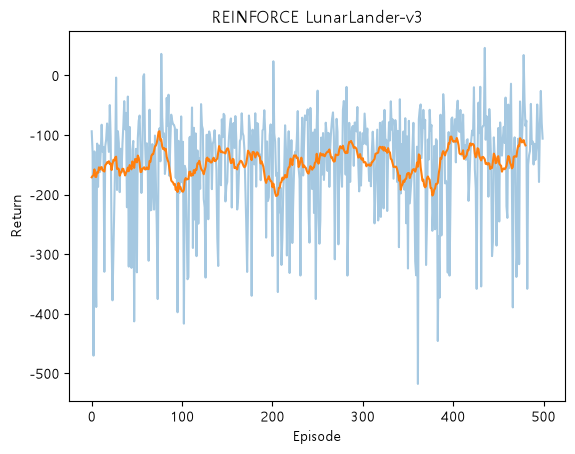

In [63]:
reinforce_model,reinforce_scores=train_reinforce(episodes=500)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE LunarLander-v3');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

강사님 코드

In [64]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions)
        )

    def forward(self, x):
        return self.net(x)

def discounted_returns(rewards,gamma=0.99):
    out=[]
    G = 0.0
    for r in reversed(rewards):
        G = float(r)+gamma*G
        out.append(G)
    return list(reversed(out))

In [70]:
# normalize_returns: Return을 정규화하여 학습을 안정적으로 진행하도록 설정하는 옵션
def train_reinforce(episodes=500, seed=2026, gamma=0.99, lr=3e-4, print_every=50, normalize_returns=True, hidden=128):
    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)
    model = PolicyNet(hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores, lengths = [], []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        rewards, log_probs = [], []

        for t in range(1000):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits  = model(x)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
            log_probs.append(dist.log_prob(action).squeeze())
            rewards.append(float(reward))
            state = next_state

            if terminated or truncated:
                break

        returns = torch.as_tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)

        if normalize_returns and len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std(unbiased=False) + 1e-8)

        loss = -(torch.stack(log_probs) * returns).mean()

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scores.append(sum(rewards))
        lengths.append(len(rewards))
        if print_every and (ep+1) % print_every == 0:
            print(f"REINFORCE {ep+1:4d}/{episodes} | 최근 50회 평균 {np.mean(scores[-50:]):8.2f}")

    env.close()
    return model, pd.DataFrame({"episode": np.arange(1, episodes+1), "reward": scores, "steps": lengths})

In [71]:
RE_EPISODES = AC_EPISODES
re_model, re_history = train_reinforce(
    episodes=RE_EPISODES, seed=2026, gamma=0.99, lr=3e-4,
    normalize_returns=True
)
print("REINFORCE 최근 50회 평균:", round(re_history.reward.tail(50).mean(),2))

REINFORCE   50/500 | 최근 50회 평균  -197.75
REINFORCE  100/500 | 최근 50회 평균  -184.26
REINFORCE  150/500 | 최근 50회 평균  -188.02
REINFORCE  200/500 | 최근 50회 평균  -115.27
REINFORCE  250/500 | 최근 50회 평균  -132.88
REINFORCE  300/500 | 최근 50회 평균  -118.10
REINFORCE  350/500 | 최근 50회 평균  -138.19
REINFORCE  400/500 | 최근 50회 평균  -124.24
REINFORCE  450/500 | 최근 50회 평균   -99.78
REINFORCE  500/500 | 최근 50회 평균  -123.51
REINFORCE 최근 50회 평균: -123.51


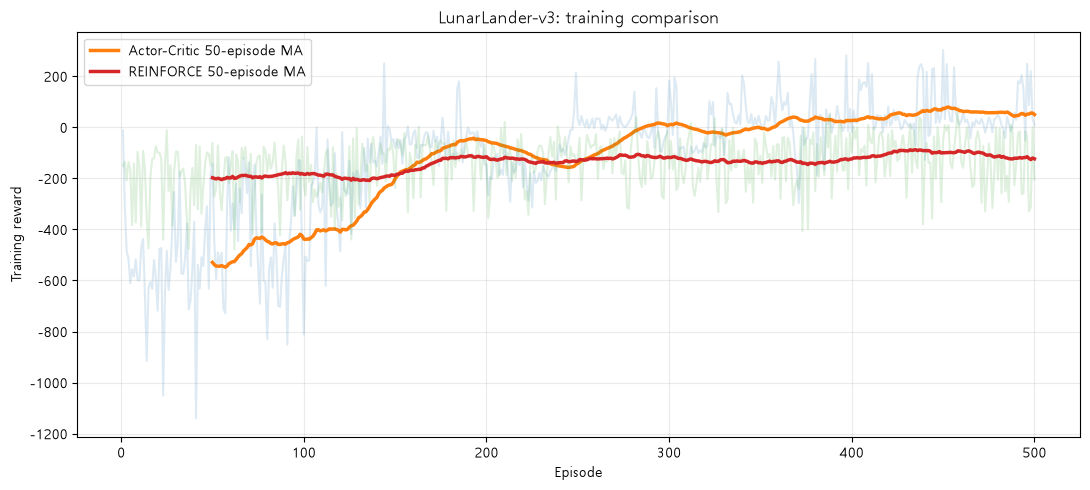

In [72]:
plt.figure(figsize=(11,5))
for name, hist in [("Actor-Critic", ac_history), ("REINFORCE", re_history)]:
    plt.plot(hist.episode, hist.reward, alpha=0.15)
    xx, yy = moving_average(hist.reward, 50)
    if len(xx): plt.plot(xx, yy, linewidth=2.5, label=f"{name} 50-episode MA")
plt.xlabel("Episode"); plt.ylabel("Training reward")
plt.title("LunarLander-v3: training comparison")
plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()

In [74]:
re_eval = evaluate_policy(re_model, episodes=30, seed=1000, greedy=True)
comparison = pd.DataFrame({
    "algorithm": ["Random (train-time baseline)", "Actor-Critic", "REINFORCE"],
    "evaluation_mean": [np.nan, ac_eval.reward.mean(), re_eval.reward.mean()],
    "evaluation_std": [np.nan, ac_eval.reward.std(), re_eval.reward.std()],
    "last_50_training_mean": [np.nan, ac_history.reward.tail(50).mean(), re_history.reward.tail(50).mean()],
})
comparison

,algorithm,evaluation_mean,evaluation_std,last_50_training_mean
0,Random (train-time baseline),NaN,NaN,NaN
1,Actor-Critic,20.616359,21.394695,49.864001
2,REINFORCE,-299.208702,43.325116,-123.514293


In [77]:
random_eval_scores = run_random_baseline(episodes=30, seed=1000)
comparison.loc[0, "evaluation_mean"] = np.mean(random_eval_scores)
comparison.loc[0, "evaluation_std"] = np.std(random_eval_scores, ddof=1)
comparison.round(2)

,algorithm,evaluation_mean,evaluation_std,last_50_training_mean
0,Random (train-time baseline),-229.32,109.42,NaN
1,Actor-Critic,20.62,21.39,49.86
2,REINFORCE,-299.21,43.33,-123.51


- 심험 A: 학습률 1e-3, 3e-4, 1e,4 비교
    - 큰 학습률은 빠른 개선 또는 불안정
    - 작은 학습률은 느린 개선과 안정성
    - 실행 경과에 따라 달라질 수 있음

- 실험 B: 할인율 0.95, 0.99 비교
    - 미래의 착륙 결과를 더 중요하게 생각하면 학습이 좋아질지 비교
    - 할인율이 작은 경우 먼 미래 보상이 상대적으로 빨리 할인됨
    - 할인율이 큰 경우 먼 미래 보상이 더 크게 반영됨
    - 할인율이 높을 수록 학습이 잘 죌 가능성이 높음

- 실험 C: 엔트로피 계수 0.0, 0.01 비교
    - 정책이 너무 일찍 특정 행동 하나에 확신하지 않도록 하면 성능이 달라질지 비교
    - entropy_coef=0: 엔트로피 보너스 없음. 행동 샘플링 자체를 확률적
    - entropy_coef=0.01: 높은 엔트로피에 약한 보상을 줌
    = 실행 결과에 따라 달라질 수 있음 